
Simulating BPSK...
Eb/N0= 0 dB | Errors=1613 | Bits=  20000 | BER=8.0650e-02
Eb/N0= 2 dB | Errors=756 | Bits=  20000 | BER=3.7800e-02
Eb/N0= 4 dB | Errors=246 | Bits=  20000 | BER=1.2300e-02
Eb/N0= 6 dB | Errors=236 | Bits= 100000 | BER=2.3600e-03
Eb/N0= 8 dB | Errors=192 | Bits=1000000 | BER=1.9200e-04
Eb/N0=10 dB | Errors=  4 | Bits=1000000 | BER=4.0000e-06
Eb/N0=12 dB | Errors=  0 | Bits=1000000 | BER=3.0000e-06 (95% upper bound; zero errors)
Eb/N0=14 dB | Errors=  0 | Bits=1000000 | BER=3.0000e-06 (95% upper bound; zero errors)

Simulating QPSK...
Eb/N0= 0 dB | Errors=3105 | Bits=  20000 | BER=1.5525e-01
Eb/N0= 2 dB | Errors=2094 | Bits=  20000 | BER=1.0470e-01
Eb/N0= 4 dB | Errors=1177 | Bits=  20000 | BER=5.8850e-02
Eb/N0= 6 dB | Errors=450 | Bits=  20000 | BER=2.2500e-02
Eb/N0= 8 dB | Errors=260 | Bits=  40000 | BER=6.5000e-03
Eb/N0=10 dB | Errors=211 | Bits= 300000 | BER=7.0333e-04
Eb/N0=12 dB | Errors= 34 | Bits=1000000 | BER=3.4000e-05
Eb/N0=14 dB | Errors=  1 | Bits=1000000

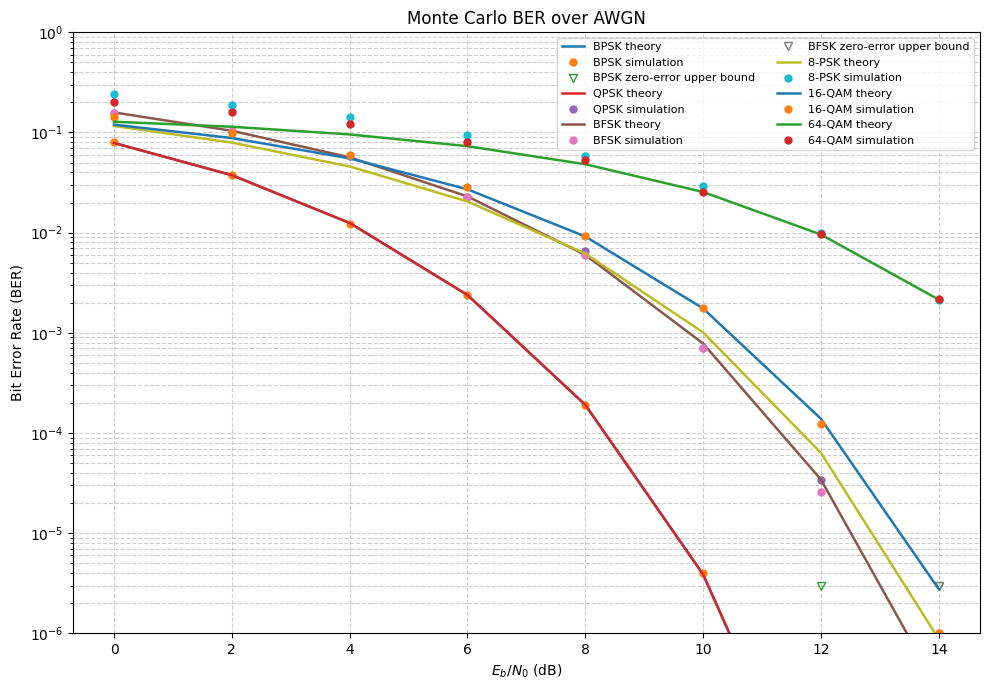

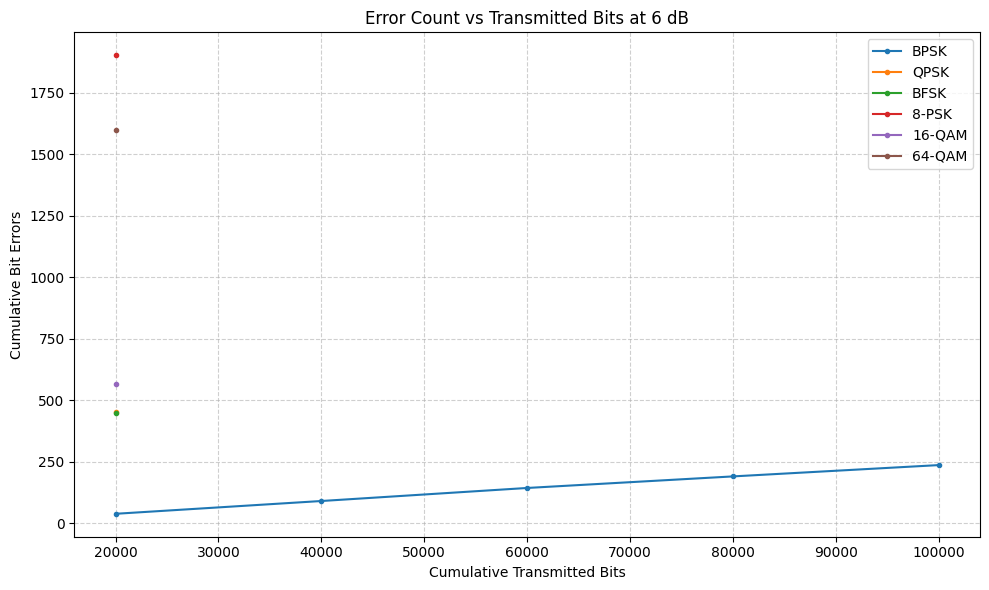


FINAL BER SUMMARY
--------------------------------------------------------------------------------------
Modulation   Eb/N0(dB)    Errors        Bits     BER / Upper Bound
--------------------------------------------------------------------------------------
BPSK                 0      1613       20000     8.0650e-02 (BER)
BPSK                 2       756       20000     3.7800e-02 (BER)
BPSK                 4       246       20000     1.2300e-02 (BER)
BPSK                 6       236      100000     2.3600e-03 (BER)
BPSK                 8       192     1000000     1.9200e-04 (BER)
BPSK                10         4     1000000     4.0000e-06 (BER)
BPSK                12         0     1000000     3.0000e-06 (Upper bound)
BPSK                14         0     1000000     3.0000e-06 (Upper bound)
QPSK                 0      3105       20000     1.5525e-01 (BER)
QPSK                 2      2094       20000     1.0470e-01 (BER)
QPSK                 4      1177       20000     5.8850e-02 (BER

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import erfc, sqrt

# ============================================================
# EXPERIMENT 12: MONTE CARLO BER OVER AWGN
# BPSK, QPSK, BFSK, 8-PSK, 16-QAM and 64-QAM
# ============================================================

# -------------------- PARAMETERS -----------------------------
EBN0_DB = np.arange(0, 15, 2)  # 0, 2, ..., 14 dB
MAX_BITS = 10**6
MAX_ERRORS = 200
BATCH_BITS = 20000
RNG = np.random.default_rng(42)

# For zero observed errors, use the approximate 95% upper
# confidence bound: BER < 3 / number_of_transmitted_bits.
ZERO_ERROR_FACTOR = 3.0

# -------------------- Q FUNCTION -----------------------------
def Q(x):
    """Gaussian Q-function."""
    x = np.asarray(x, dtype=float)
    return np.vectorize(
        lambda z: 0.5 * erfc(z / sqrt(2))
    )(x)


# -------------------- GRAY CODE HELPERS ----------------------
def gray_decode(g):
    """Convert a Gray-coded integer to its binary index."""
    b = g
    shift = g >> 1
    while shift:
        b ^= shift
        shift >>= 1
    return b


def gray_encode(b):
    """Convert a binary index to its Gray-coded integer."""
    return b ^ (b >> 1)


# -------------------- CONSTELLATIONS -------------------------
def make_constellation(name):
    """
    Returns:
        points: complex constellation symbols
        labels: integer bit labels corresponding to points
        k: bits per symbol
        eb: average energy per bit (normalized to 1)
    """
    if name == "BPSK":
        k = 1
        labels = np.arange(2)
        points = np.array([-1, 1], dtype=complex)

    elif name == "QPSK":
        k = 2
        labels = np.arange(4)
        # Gray-labelled phase sequence
        phase_indices = np.array(
            [gray_decode(int(x)) for x in labels]
        )
        points = np.exp(1j * 2 * np.pi * phase_indices / 4)

    elif name == "BFSK":
        # Coherent orthogonal BFSK in two-dimensional signal space.
        # The points are vectors (I, Q), not antipodal BPSK points.
        k = 1
        labels = np.arange(2)
        points = np.array([1 + 0j, 0 + 1j])

    elif name == "8-PSK":
        k = 3
        labels = np.arange(8)
        phase_indices = np.array(
            [gray_decode(int(x)) for x in labels]
        )
        points = np.exp(1j * 2 * np.pi * phase_indices / 8)

    elif name in ("16-QAM", "64-QAM"):
        M = 16 if name == "16-QAM" else 64
        k = int(np.log2(M))
        m = int(np.sqrt(M))
        axis_bits = k // 2

        # Average symbol energy normalized to k, so Eb = 1.
        raw_levels = np.arange(-(m - 1), m, 2)
        scale = np.sqrt(3 * k / (2 * (m**2 - 1)))
        levels = raw_levels * scale

        labels = np.arange(M)
        points = []

        for label in labels:
            # Split each label into I and Q bit groups.
            i_gray = int(label) >> axis_bits
            q_gray = int(label) & (m - 1)

            i_index = gray_decode(i_gray)
            q_index = gray_decode(q_gray)

            points.append(
                levels[i_index] + 1j * levels[q_index]
            )

        points = np.array(points, dtype=complex)

    else:
        raise ValueError("Unknown modulation scheme")

    # Every scheme has average Eb = 1.
    # For BFSK, Es = Eb = 1.
    return points, labels, k


# -------------------- BIT CONVERSION -------------------------
def bits_to_integers(bits, k):
    """Convert groups of k bits to unsigned integer labels."""
    groups = bits.reshape(-1, k)
    weights = 2 ** np.arange(k - 1, -1, -1)
    return groups @ weights


def integers_to_bits(labels, k):
    """Convert integer labels back to MSB-first bit streams."""
    shifts = np.arange(k - 1, -1, -1)
    return ((labels[:, None] >> shifts) & 1).astype(np.uint8)


# -------------------- THEORY BER -----------------------------
def theoretical_ber(name, ebn0_db):
    """Standard AWGN BER expressions."""
    gamma = 10 ** (ebn0_db / 10)

    if name == "BPSK":
        return float(Q(sqrt(2 * gamma)))

    if name == "QPSK":
        return float(Q(sqrt(2 * gamma)))

    if name == "BFSK":
        # Coherent orthogonal binary FSK
        return float(Q(sqrt(gamma)))

    if name == "8-PSK":
        M = 8
        k = 3
        # Common Gray-coded BER approximation
        return float(
            (2 / k) *
            Q(sqrt(2 * k * gamma) * np.sin(np.pi / M))
        )

    if name in ("16-QAM", "64-QAM"):
        M = 16 if name == "16-QAM" else 64
        k = int(np.log2(M))
        a = sqrt(3 * k * gamma / (M - 1))
        q = float(Q(a))
        # Standard Gray-coded square-QAM BER approximation
        return (4 / k) * (1 - 1 / sqrt(M)) * q * (
            1 - (1 - 1 / sqrt(M)) * q
        )

    raise ValueError("Unknown modulation scheme")


# -------------------- MONTE CARLO SIMULATION -----------------
def simulate_ber(name, ebn0_db, save_trace=False):
    points, labels, k = make_constellation(name)

    # Build a reverse lookup from each constellation point
    # to its original binary label.
    bits_per_label = integers_to_bits(labels, k)

    gamma = 10 ** (ebn0_db / 10)
    N0 = 1.0 / gamma
    noise_std = sqrt(N0 / 2)

    total_bits = 0
    total_errors = 0
    trace_bits = []
    trace_errors = []

    while total_bits < MAX_BITS and total_errors < MAX_ERRORS:
        nbits = min(BATCH_BITS, MAX_BITS - total_bits)

        # Each complete symbol carries k bits.
        nbits -= nbits % k
        if nbits == 0:
            break

        tx_bits = RNG.integers(0, 2, size=nbits, dtype=np.uint8)
        tx_labels = bits_to_integers(tx_bits, k)

        # Modulation: Eb is normalized to 1.
        tx_symbols = points[tx_labels]

        # Complex AWGN: variance N0/2 per real dimension.
        noise = noise_std * (
            RNG.standard_normal(len(tx_symbols))
            + 1j * RNG.standard_normal(len(tx_symbols))
        )
        rx_symbols = tx_symbols + noise

        # Coherent maximum-likelihood detection.
        # Chunked distance calculation controls memory use.
        detected_labels = np.empty(len(rx_symbols), dtype=int)
        detect_chunk = 5000

        for start in range(0, len(rx_symbols), detect_chunk):
            stop = min(start + detect_chunk, len(rx_symbols))
            r = rx_symbols[start:stop]

            distances = np.abs(
                r[:, None] - points[None, :]
            ) ** 2

            nearest_indices = np.argmin(distances, axis=1)
            detected_labels[start:stop] = labels[nearest_indices]

        rx_bits = bits_per_label[detected_labels].reshape(-1)

        errors = int(np.count_nonzero(tx_bits != rx_bits))
        total_errors += errors
        total_bits += nbits

        if save_trace:
            trace_bits.append(total_bits)
            trace_errors.append(total_errors)

    # Never report zero as a measured BER when no errors occur.
    if total_errors == 0:
        ber = ZERO_ERROR_FACTOR / total_bits
        zero_error = True
    else:
        ber = total_errors / total_bits
        zero_error = False

    return {
        "ber": ber,
        "errors": total_errors,
        "bits": total_bits,
        "zero_error": zero_error,
        "trace_bits": np.array(trace_bits),
        "trace_errors": np.array(trace_errors),
    }


# -------------------- RUN ALL SIX SCHEMES --------------------
schemes = [
    "BPSK", "QPSK", "BFSK",
    "8-PSK", "16-QAM", "64-QAM"
]

results = {
    name: {"theory": [], "sim": [], "errors": [], "bits": [],
           "zero": [], "traces": []}
    for name in schemes
}

# Save cumulative error traces at this Eb/N0 point.
TRACE_EBN0_DB = 6

for name in schemes:
    print(f"\nSimulating {name}...")

    for snr_db in EBN0_DB:
        keep_trace = (snr_db == TRACE_EBN0_DB)

        out = simulate_ber(name, snr_db, save_trace=keep_trace)

        results[name]["theory"].append(
            theoretical_ber(name, snr_db)
        )
        results[name]["sim"].append(out["ber"])
        results[name]["errors"].append(out["errors"])
        results[name]["bits"].append(out["bits"])
        results[name]["zero"].append(out["zero_error"])

        if keep_trace:
            results[name]["traces"] = (
                out["trace_bits"], out["trace_errors"]
            )

        print(
            f"Eb/N0={snr_db:2d} dB | "
            f"Errors={out['errors']:3d} | "
            f"Bits={out['bits']:7d} | "
            f"BER={out['ber']:.4e}"
            + (" (95% upper bound; zero errors)" if out["zero_error"] else "")
        )


# -------------------- PLOT 1: BER CURVES ---------------------
plt.figure(figsize=(10, 7))

for name in schemes:
    theory = np.array(results[name]["theory"])
    simulated = np.array(results[name]["sim"])
    zero = np.array(results[name]["zero"], dtype=bool)

    plt.semilogy(
        EBN0_DB, theory, "-", linewidth=1.8,
        label=f"{name} theory"
    )

    # Zero-error points are upper bounds, not measured BERs.
    plt.semilogy(
        EBN0_DB[~zero], simulated[~zero],
        "o", markersize=5, label=f"{name} simulation"
    )

    if np.any(zero):
        plt.semilogy(
            EBN0_DB[zero], simulated[zero],
            "v", markersize=6, markerfacecolor="none",
            linestyle="none", label=f"{name} zero-error upper bound"
        )

plt.xlabel(r"$E_b/N_0$ (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("Monte Carlo BER over AWGN")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.ylim(1e-6, 1)
plt.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()


# -------------------- PLOT 2: ERROR COUNT VS BITS ------------
plt.figure(figsize=(10, 6))

for name in schemes:
    trace_bits, trace_errors = results[name]["traces"]

    if len(trace_bits) > 0:
        plt.plot(
            trace_bits, trace_errors, marker="o",
            markersize=3, linewidth=1.5, label=name
        )

plt.xlabel("Cumulative Transmitted Bits")
plt.ylabel("Cumulative Bit Errors")
plt.title(f"Error Count vs Transmitted Bits at {TRACE_EBN0_DB} dB")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


# -------------------- FINAL SUMMARY TABLE --------------------
print("\nFINAL BER SUMMARY")
print("-" * 86)
print(
    f"{'Modulation':<12}{'Eb/N0(dB)':>10}"
    f"{'Errors':>10}{'Bits':>12}{'BER / Upper Bound':>22}"
)
print("-" * 86)

for name in schemes:
    for i, snr_db in enumerate(EBN0_DB):
        label = "Upper bound" if results[name]["zero"][i] else "BER"
        print(
            f"{name:<12}{snr_db:>10}"
            f"{results[name]['errors'][i]:>10}"
            f"{results[name]['bits'][i]:>12}"
            f"{results[name]['sim'][i]:>15.4e} ({label})"
        )

print("\nSimulation completed.")